# E75: Can Qwen3-1.7B's clean-model table fail a bad placement, and does RL read as the fine-tunes?

## The answer

The clean-model table can fail a bad placement of the right size, where size means Frobenius norm per matrix. Three wrong changes read further from the updated model than the remainder on all five updates; the narrowest clears by 1.7 times its bootstrap width. It still barely separates same-size parts of the update, and size weighted by the inputs is untested. RL's update, its shuffled-reward null and training on the model's own correct samples read the same filed labels but for one no-call. So those labels separate neither reward nor samples, and RL's update is not called learning here.

**Where a lean missed.** We leaned that the random change and another update's change would read near the ruler. Random did. Another update's read about half the ruler on the first and gold fine-tunes, and no read here tests why.


## What we were trying to test

The first deliverable is a map on Qwen3-1.7B judged by a test that can fail a bad placement, and the user chose the clean-model table as that test. The second is the same table for fine-tuning and RL updates.

**The table.** Each matrix is $W_0 = U V^\top + \Delta$, and an update $\delta W$ changes the weights. A state is $W_0$ plus some part of $\delta W$, run with no masks. Its score is $K = \mathrm{KL}(\text{updated model} \,\|\, \text{state})$. The updated model reads 0, the original model $W_0$ reads the ruler, and figures divide by that ruler. Γ plays no role.

**The updates.** Three saved fine-tunes, RL's GRPO run at steps 100 and 10, the same run with rewards shuffled, which is the null, and supervised fine-tuning on the model's own correct samples, drawn once from $W_0$, which is the own-samples arm. The last asks whether RL's rows come from RL's samples without the reward's weighting. The template fine-tune reads its own 64 rows; the rest read 128 maths rows, text RL did not train on.

**The states.**

- *In-span part:* the part of the least-squares split inside the subcomponents, the candidate.
- *Remainder:* what that split sends to Δ, and the bar the wrong changes must clear.
- *Rescaled update:* $W_0 + t\,\delta W$, with $t$ the part's input-weighted norm over the update's. It tests whether size alone explains a score.
- *Random slice:* a random output-side subspace of $\delta W$ at the part's input-weighted energy. It is still part of the update.
- *Three wrong changes:* per matrix at $\delta W$'s Frobenius norm, a Gaussian matrix, another update's matrix, or $\delta W$ with a random sign per matrix. These rule out a table that passes anything of the right size.
- *Often-on and rarely-on halves, adjoint split:* other placements of the same update.

**The masked read.** Under $W_0$'s masks with Δ off, $\tau$ is the share of the whole update's clean KL that reaches the output: 1 as in the clean model, 0 nothing.


In [1]:
from pathlib import Path

from IPython.display import Image, Markdown, display

from commute.jobs import load_experiment

plot = load_experiment("qwen_rl_reads", "plot")
rules = load_experiment("qwen_rl_reads", "rules")
# run.py rewrites score.json with only its own job's updates, so the five are rescored from the reads with the filed rules.
SCORE = plot.rescore(rules)
NAMES = [u for u, *_ in plot.UPDATES]


def show(name):
    display(Image(filename=str(Path(plot.FIG) / name), width=760))


def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


## What we expected, and why

We filed medium leans for RL only: the update barely reaches the output under $W_0$'s masks, random reads at least ten times further than the larger half, and the in-span part reads below the remainder. No lean on the in-span part against its slice, or on the null and the own-samples arm, so nothing can hold or miss on those two. For the wrong changes we leaned that all three fail everywhere and, with no rule, that random and another update's read near the ruler.


## What we observed

### Which states does the table fail?


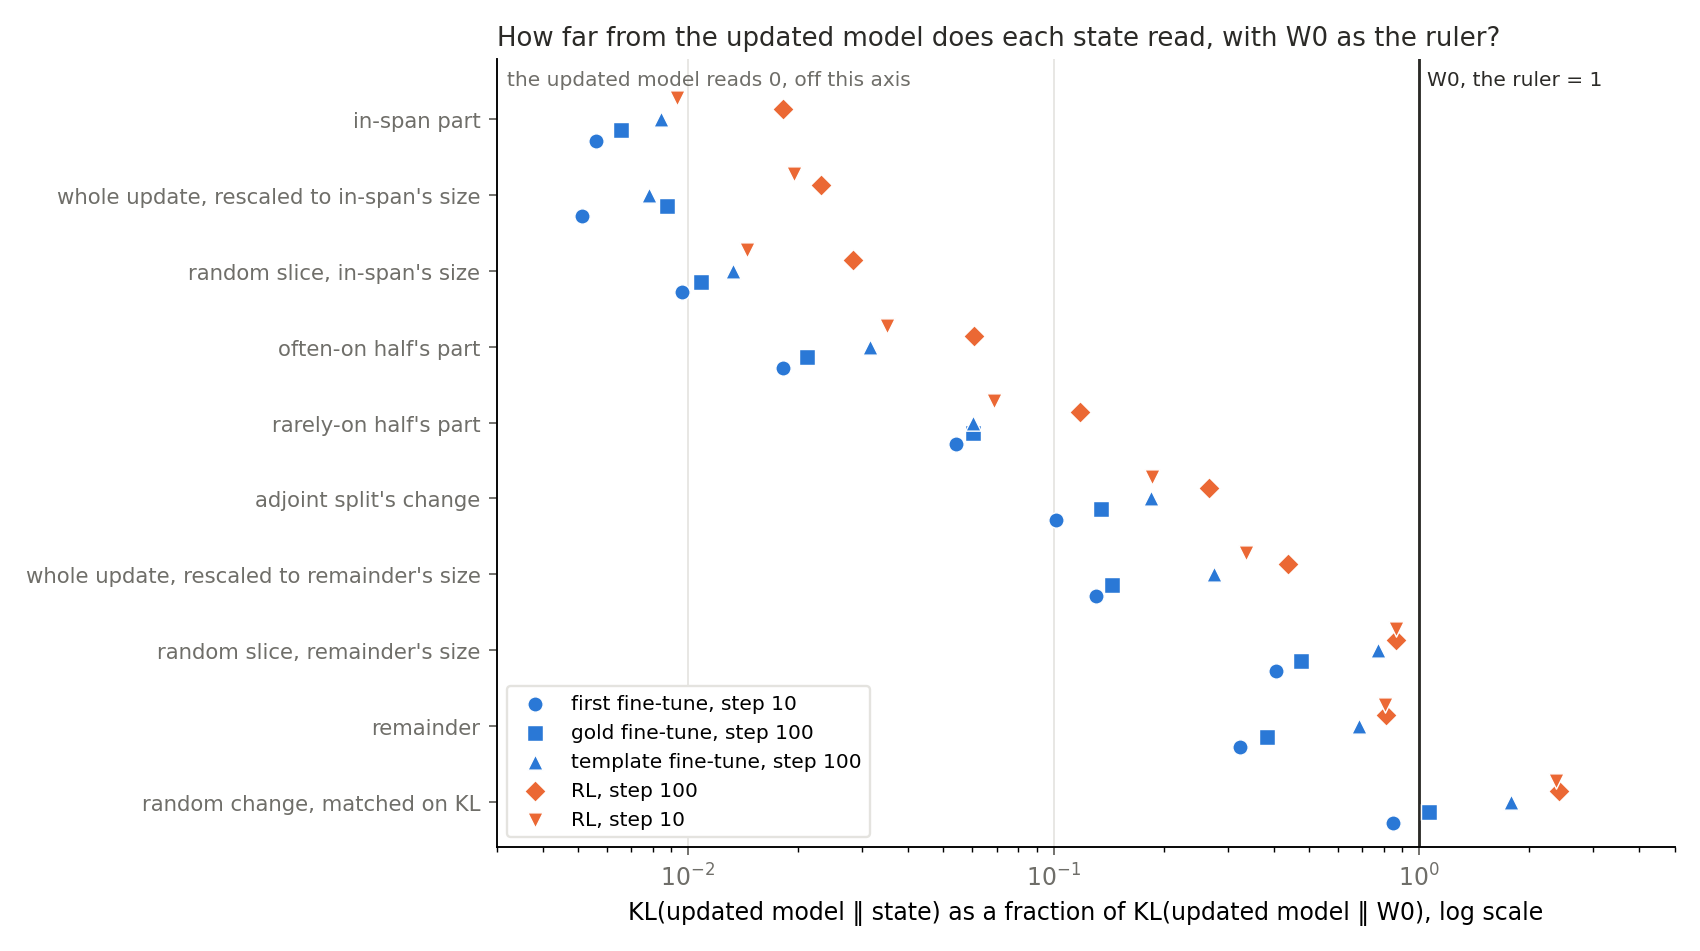

In [2]:
show("k_fraction.png")


**Reading it.** The candidates form one ladder on every update, with the in-span part lowest and the remainder near the top. The random change here has its scale searched until it moves $W_0$ as far as the update does, which takes 18 to 100 times the update's size. So its reading of 0.85 to 2.4 of the ruler is not a read at the right size. A later section reads that.


### Does the in-span part beat a state of its size that is not placed?


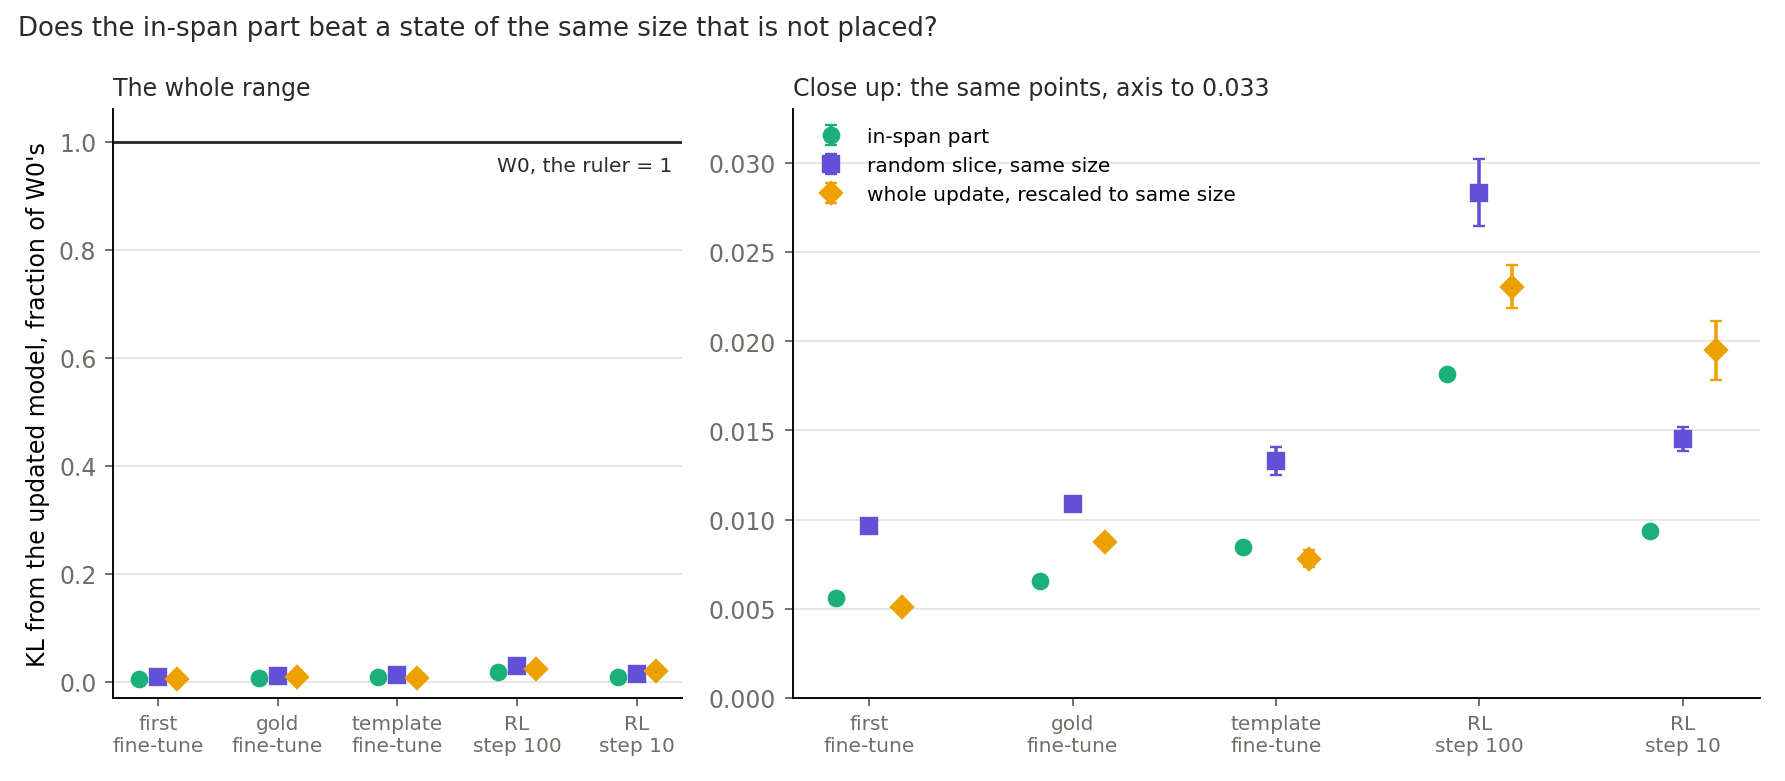

In [3]:
show("beats_size.png")


**Reading it.** By the filed rule yes, on all five updates, and the margin is small. On the first fine-tune the in-span part reads 0.009 nats and its slice 0.016, against the ruler's 1.635. The gap is 0.4 to 1.0 percent of the ruler. The rescaled update, with no placement at all, reads closer than the in-span part on the first and template fine-tunes. So the table barely separates same-size parts of the update. In 82 of the 196 matrices the remainder is zero to rounding, so all three states are the same weights there.


### Does the table fail a wrong change of the right size?


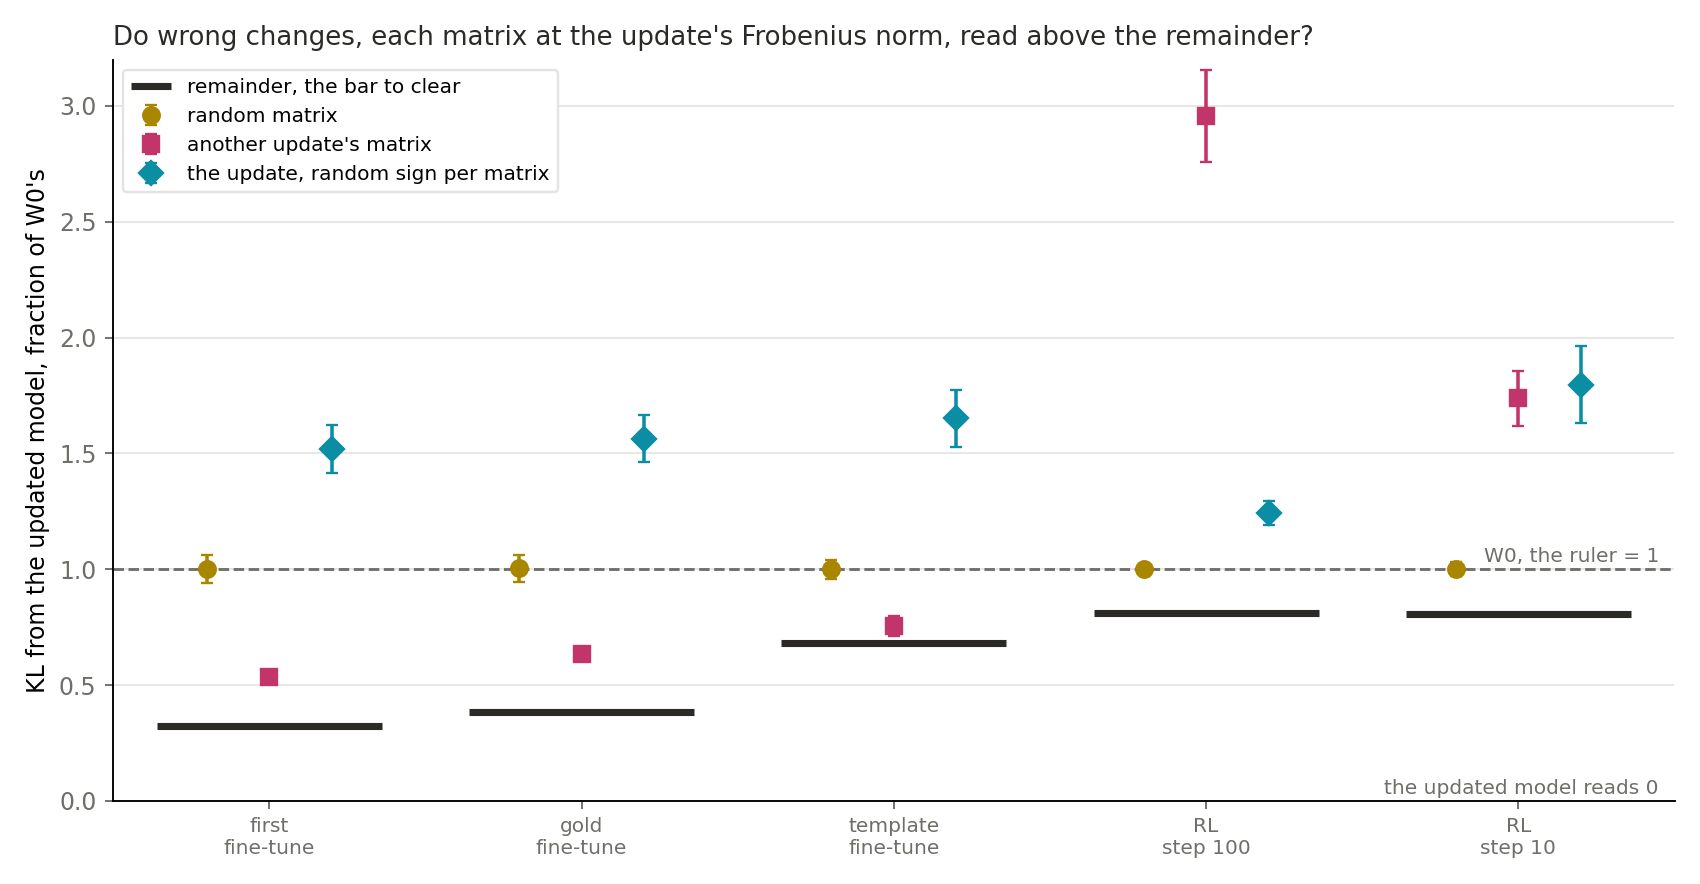

In [4]:
show("bad_placements.png")


**Reading it.** Yes: all three wrong changes read above the remainder on all five updates, the filed label "has teeth". The narrowest case is another update's matrix on the template fine-tune, a gap of 0.023 nats against a half-width of 0.014. The next narrowest is 5.9 times its half-width.

The caveat is size. It is Frobenius norm per matrix, and neither random's nor another update's input-weighted size was measured. Random reads 1.00 of the ruler, as $W_0$ does, and $W_0$ already fails this bar, so random adds little. Signs is the exception: a sign leaves each matrix's input-weighted size unchanged, and it reads 1.2 to 1.8 of the ruler.

**The lean that missed.** Another update's matrix was to read near the ruler. It reads 0.54 and 0.63 on the first and gold fine-tunes, and 2.96 and 1.74 on RL. No read here tests why it reads low, and we name no cause. It still clears the bar.


### Does RL's update read as the fine-tunes do?


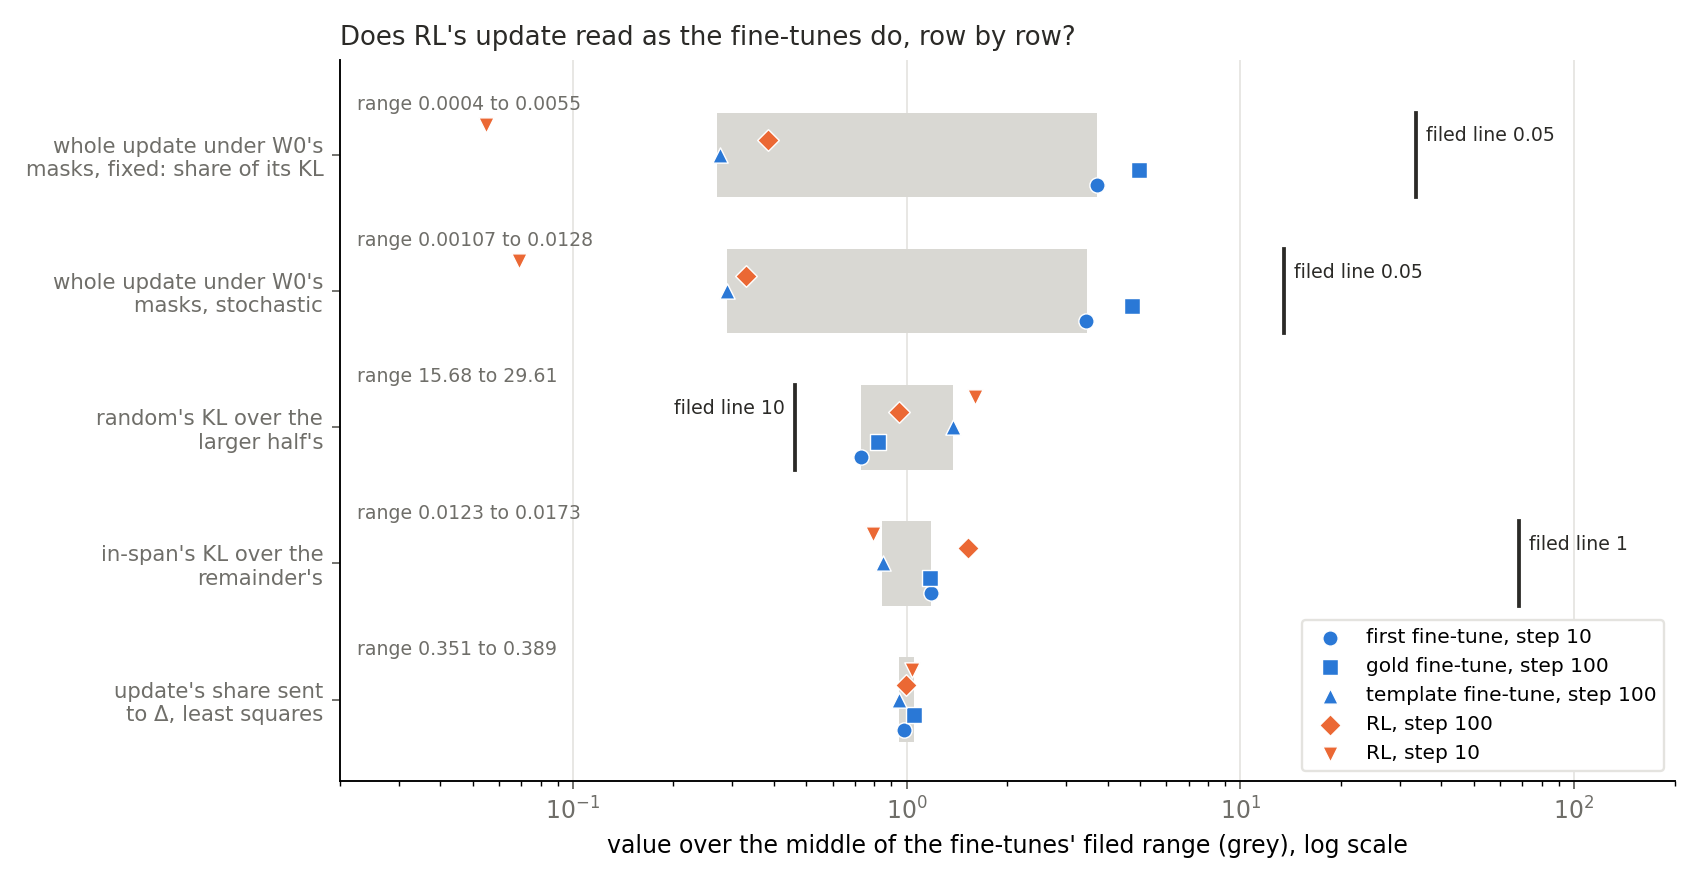

In [5]:
show("against_sft.png")


**Reading it.** RL at step 100 mostly does, and RL at step 10 mostly does not, though no filed label changed. At step 100 only in-span over remainder leaves the grey range. At step 10 all four rule rows leave it. The range is thin evidence, from three updates, or two on the masked rows, and the gold fine-tune falls outside those two. The next section sets this against the null.


### Does the table separate RL's update from its shuffled-reward null?


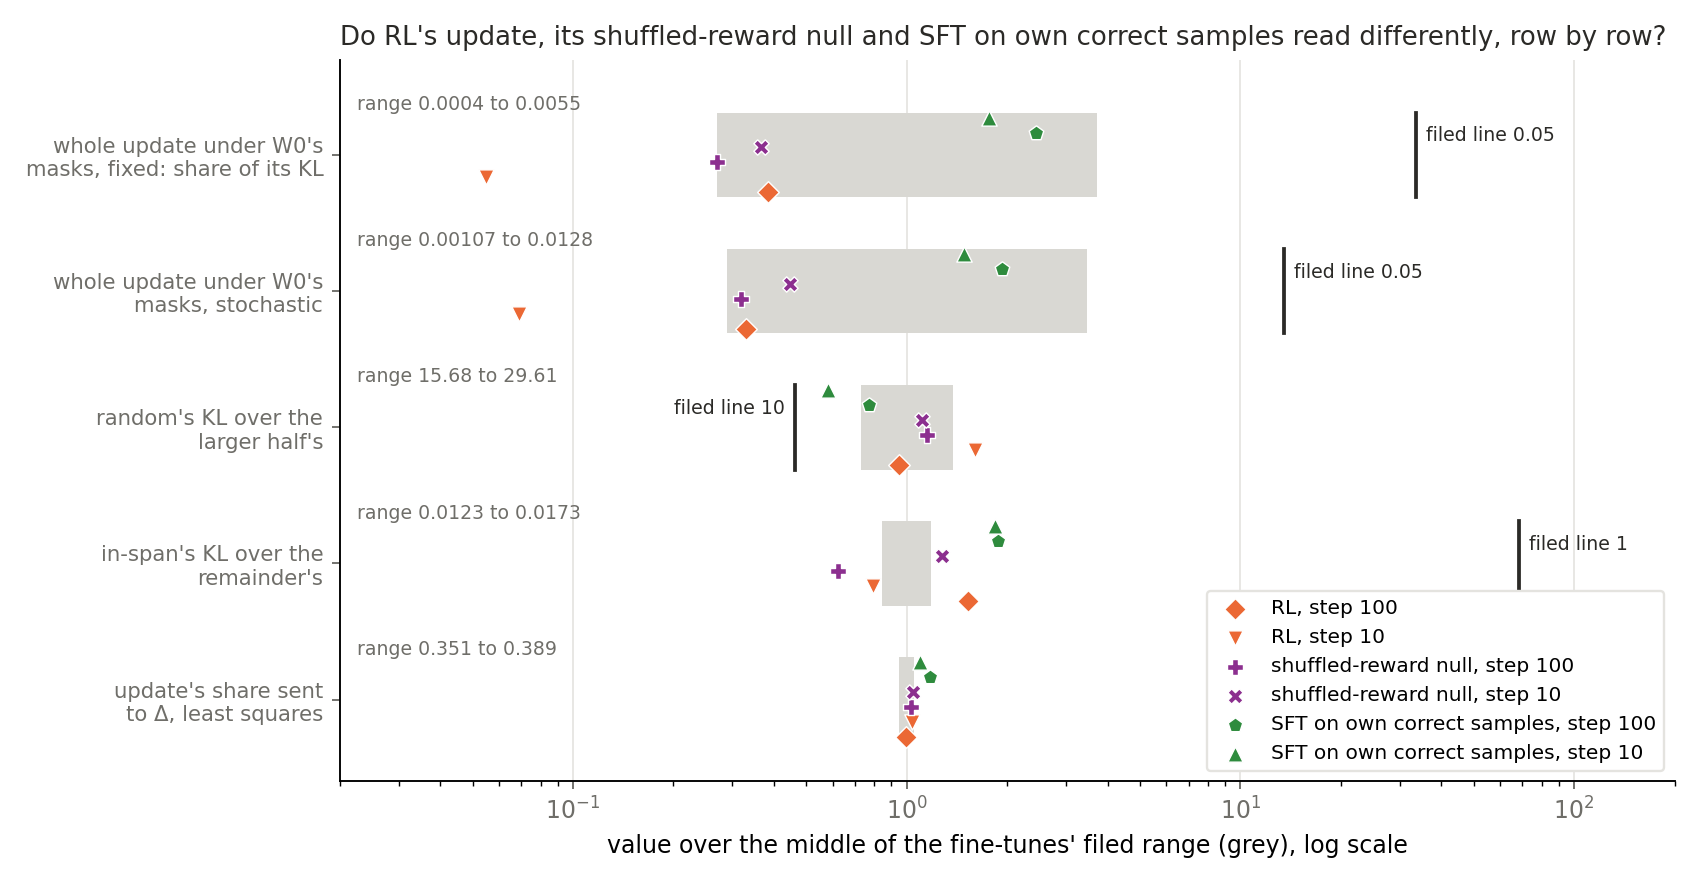

In [6]:
show("r_vs_n.png")


**Reading it.** No, on the filed labels: at each step the three arms read the same labels, masked rows included, with one no-call. That no-call is the own-samples arm at step 10 on the in-span part against its slice, where both reads are under the rule's floor of 1e-5 nats. No lean was filed on the null or the own-samples arm. The values differ, and nothing filed reads the difference, since each arm is one seed and no noise floor between arms was measured.

Two differences stand out. KL(updated model ‖ $W_0$), the ruler, reads 0.0010 nats on the own-samples arm at step 100, against 0.064 on RL and 0.135 on the null. Its input-weighted energy is 0.37 of RL's. It is also the only arm of the three outside the fine-tunes' range on the update's share sent to Δ, at 0.44 and 0.41. No row has RL and another arm leaving that range the same way at both steps, so these reads do not assign RL's departures to the reward or to the samples.

This does not call RL's update learning. The null also gained accuracy, cause not established, and RL's lead over it may be largely answer format, by the RL lead's note.


### Why is the gain unscored on RL, and how small is RL's ruler?


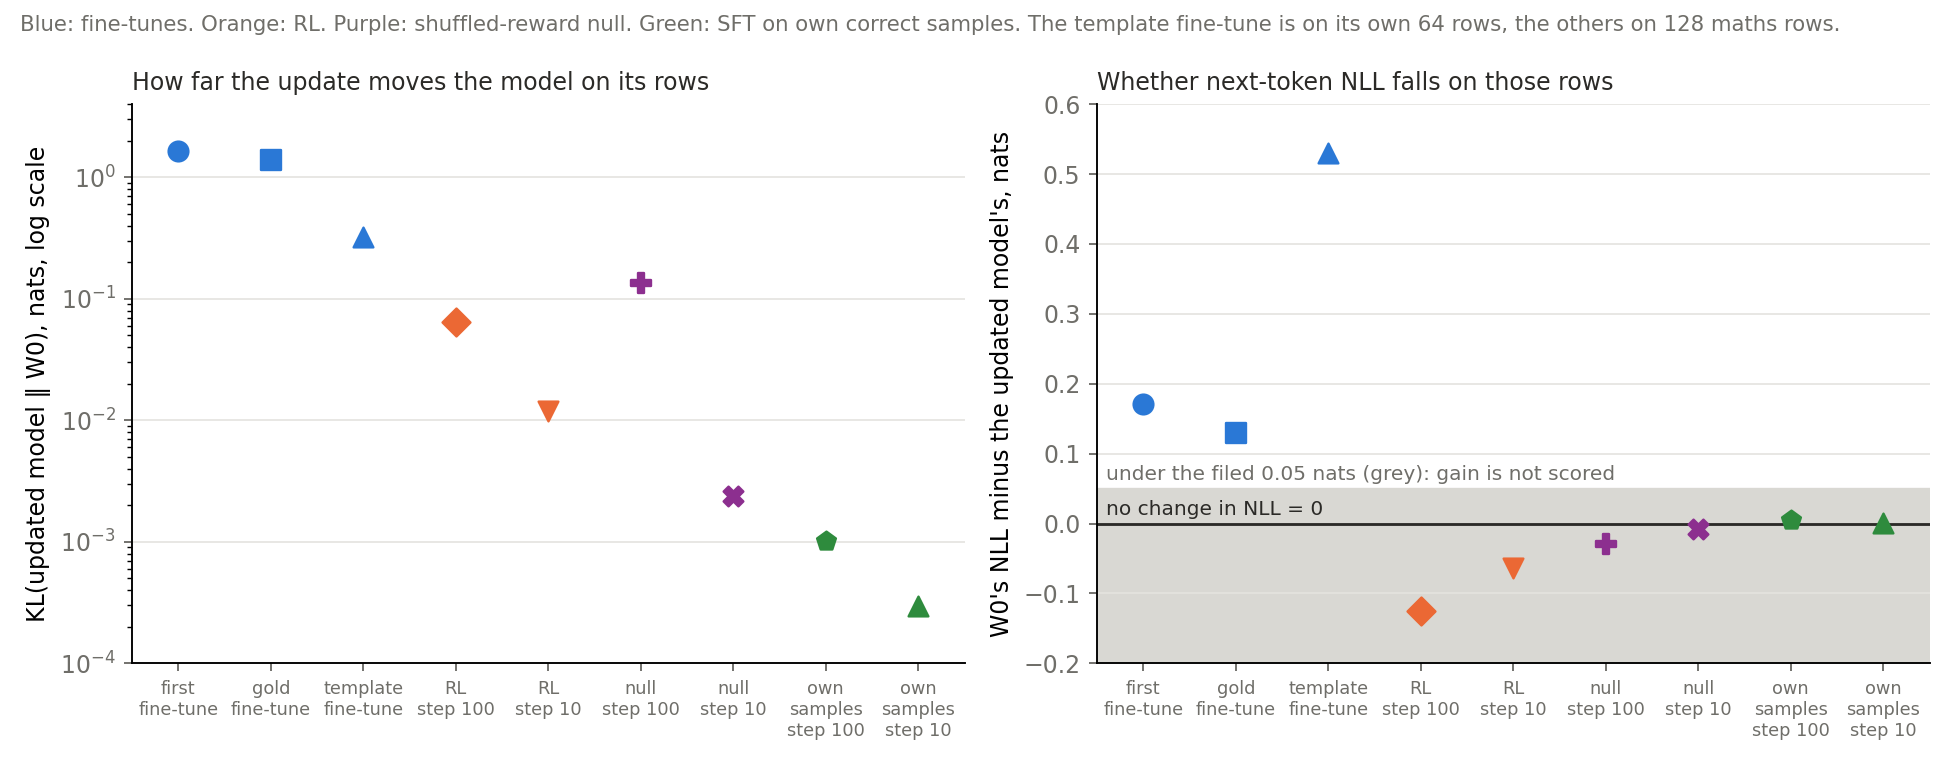

In [7]:
show("ruler.png")


**Reading it.** The gain cannot be read on RL because RL's update raises next-token NLL on these rows, and the filed rule needs a fall of at least 0.05 nats. The null raises it as well. The own-samples arm lowers it, but by under 0.005 nats, so it is unscored too. RL's ruler is also small here, 0.064 nats at step 100 against 1.6 on the first fine-tune, and the own-samples arm's is smaller again. None of this speaks to accuracy on RL's own task.


## What we learned

The clean-model table fails wrong changes at the update's Frobenius norm on every update read, so the first deliverable's test can fail a wrong direction. It barely grades same-size parts of the update against each other. For the second deliverable, RL's labels are also those of its null and, but for one no-call, of the own-samples arm, so they carry no statement about reward or samples.

## How compelling is the evidence

- **Control.** The first fine-tune reproduced every stored number with a gap of 0, first and alone, in each job.
- **Coverage.** Five updates, and the null and the own-samples arm at two steps each. One slice seed, one seed per wrong change, one training seed per arm.
- **Blind spots.** $K$ is not accuracy or gain. Only signs is the right input-weighted size. The bar, the remainder, is itself 0.35 to 0.39 of the update's input-weighted norm.
- **Noise.** The bootstrap covers rows only, so the real noise is larger than the bars.

## Surprises

**A lean with no rule missed:** another update's matrix did not read near the ruler, as above. Every filed label came out as leaned. Also, the rescaled update beat the in-span part on two fine-tunes, and on RL, the null and the own-samples arm it reads close to the square law $(1-t)^2$ of the ruler, where on the fine-tunes it reads well below.

## What next

1. **More slice seeds and a floor between arms.** These say whether a margin under one percent, and the differences among RL, the null and the own-samples arm, are stable.
2. **Wrong changes sized by input weighting.** If one reads at or below the remainder, the table goes back to the user. This goes through `/design`.

## Scorecard


In [8]:
def cell(u, row, digits=3):
    r = SCORE[u]["rows"][row]
    return f"{r['value']:.{digits}g} {r['read']}, {r['against_sft']}"


rows = [["control", "first fine-tune reproduces stored reads", "within 1e-3 relative", "gap 0", "passed"]]
rows.append(["transmission, fixed", "whole update barely reaches output", "at most 0.05 'deaf', at least 0.25 'carries'",
             "; ".join(f"{u} {cell(u, 'transmission_fixed')}" for u in NAMES), "as leaned on R100, R10"])
rows.append(["transmission, stochastic", "same under stochastic masks", "same", "; ".join(f"{u} {cell(u, 'transmission_stochastic')}" for u in NAMES), "as leaned on R100, R10"])
rows.append(["random_vs_halves", "random at least ten times the larger half", "ratio at least 10", "; ".join(f"{u} {cell(u, 'random_vs_halves')}" for u in NAMES), "as leaned on R100, R10"])
rows.append(["inspan_vs_remainder", "in-span below remainder", "ratio below 1", "; ".join(f"{u} {cell(u, 'inspan_vs_remainder')}" for u in NAMES), "as leaned on R100, R10"])
rows.append(["placement_vs_size", "in-span beats its slice", "gap above the bootstrap half-width", "; ".join(f"{u} {SCORE[u]['size']['gap_inspan']:.3g} ± {SCORE[u]['size']['width_inspan']:.2g}" for u in NAMES), "beats size on all; no lean filed"])
rows.append(["T2 label", "E72's gain label, no lean", "unscored under 0.05 nats", "; ".join(f"{u} {SCORE[u]['clean']['T2']}" for u in NAMES), "reported"])
bad = plot.load(plot.RES / "amend1_score.json")
null = plot.load(plot.RES / "score_N.json")
own = plot.load(plot.RES / "score_F.json")
rows.append(["bad placements", "three wrong changes above the remainder", "gap above the half-width, every state and update", bad["overall"], "as leaned"])
rows.append(["near the ruler", "random and another update's read near the ruler", "no rule, read only",
             "; ".join(f"{u} {bad['table'][u]['random']['over_ruler']:.2f}, {bad['table'][u]['other']['over_ruler']:.2f}" for u in NAMES), "random as leaned; other missed"])
rows.append(["null labels", "the same rules on the null", "as above",
             "; ".join(f"{u} " + ", ".join(null[u]["rows"][r]["read"] for r in ("transmission_fixed", "transmission_stochastic", "random_vs_halves", "inspan_vs_remainder")) for u in ("N100", "N10")), "same as RL; no lean filed"])


def own_labels(u):
    labels = [f"{own[u]['rows'][r]['read']} {own[u]['rows'][r]['value']:.3g}" for r in ("transmission_fixed", "transmission_stochastic", "random_vs_halves", "inspan_vs_remainder")]
    return f"{u} " + ", ".join(labels + [own[u]["size"]["placement_beats_size"], own[u]["clean"]["T2"]])


rows.append(["own-samples labels", "the same rules on the own-samples arm", "as above", "; ".join(own_labels(u) for u in ("F100", "F10")), "same as RL but one no call; no lean filed"])
table(["id", "claim", "rule", "read", "verdict"], rows)


| id | claim | rule | read | verdict |
|---|---|---|---|---|
| control | first fine-tune reproduces stored reads | within 1e-3 relative | gap 0 | passed |
| transmission, fixed | whole update barely reaches output | at most 0.05 'deaf', at least 0.25 'carries' | u1 0.0055 deaf, inside; u2 0.00739 deaf, outside; u3 0.00041 deaf, inside; R100 0.000571 deaf, inside; R10 8.12e-05 deaf, outside | as leaned on R100, R10 |
| transmission, stochastic | same under stochastic masks | same | u1 0.0128 deaf, inside; u2 0.0175 deaf, outside; u3 0.00107 deaf, inside; R100 0.00122 deaf, inside; R10 0.000255 deaf, outside | as leaned on R100, R10 |
| random_vs_halves | random at least ten times the larger half | ratio at least 10 | u1 15.7 holds, inside; u2 17.7 holds, inside; u3 29.6 holds, inside; R100 20.4 holds, inside; R10 34.5 holds, outside | as leaned on R100, R10 |
| inspan_vs_remainder | in-span below remainder | ratio below 1 | u1 0.0173 holds, inside; u2 0.0171 holds, inside; u3 0.0124 holds, inside; R100 0.0223 holds, outside; R10 0.0116 holds, outside | as leaned on R100, R10 |
| placement_vs_size | in-span beats its slice | gap above the bootstrap half-width | u1 0.0066 ± 0.00033; u2 0.00596 ± 0.00043; u3 0.00156 ± 0.00025; R100 0.000654 ± 0.00012; R10 6.13e-05 ± 7.9e-06 | beats size on all; no lean filed |
| T2 label | E72's gain label, no lean | unscored under 0.05 nats | u1 carried; u2 carried; u3 carried; R100 unscored; R10 unscored | reported |
| bad placements | three wrong changes above the remainder | gap above the half-width, every state and update | has teeth | as leaned |
| near the ruler | random and another update's read near the ruler | no rule, read only | u1 1.00, 0.54; u2 1.00, 0.63; u3 1.00, 0.75; R100 1.00, 2.96; R10 1.00, 1.74 | random as leaned; other missed |
| null labels | the same rules on the null | as above | N100 deaf, deaf, holds, holds; N10 deaf, deaf, holds, holds | same as RL; no lean filed |
| own-samples labels | the same rules on the own-samples arm | as above | F100 deaf 0.00361, deaf 0.00714, holds 16.6, holds 0.0273, beats size, unscored; F10 deaf 0.00262, deaf 0.00549, holds 12.5, holds 0.0269, no call, unscored | same as RL but one no call; no lean filed |

Here u1, u2 and u3 are the first, gold and template fine-tunes, R100 and R10 are RL at steps 100 and 10, N100 and N10 are the null, and F100 and F10 are the own-samples arm.

## Departures from the literature

The clean table, the wrong changes and their bar are ours and are not VPD's checks, which use stochastic, adversarial and CI-masked reconstruction. The masked read uses $W_0$'s masks with Δ off, adds the update unmasked, and draws stochastic masks once per row where the library draws afresh. RL's update, its null and the own-samples arm use the RL lead's recipe, whose departures are in that plan; the own-samples arm's samples are fixed at $W_0$, where the scoping report's matched arm sampled from current weights.

## Not run

1. Wrong changes sized by input weighting, on the null or the own-samples arm, or at more than one seed; any test of why another update's reads low, or of why the own-samples arm's ruler is small.
2. More than one slice seed; a noise floor for $K$ below 1e-6 or between arms.
3. Masked reads under the updated model's masks; any adversary; accuracy of any part; a second training seed.

Provenance: jobs 50596, 50755, 50779 and 50874, one cluster L40 each, $0. Full tables in `reports/analyses/2026-11-03_analysis_e75-rl-reads.md`.
